# 35 — Compare slope and relative elevation with orientation-invariant retrieval

**Lunar terrain → saved CNN with rotations + reflections → ranked Earth terrain → slope and height comparisons.** Run notebook 34 first, then set `ORIENTATION_RUN` below to its completed cache. Existing notebook-28 terrain and notebook-29 weights are reused on CPU; no training or scaler fitting occurs.

Use both **slope magnitude** (steepness and its spatial pattern) and **relative elevation** (ridges, depressions and their vertical scale). Each height map has its patch mean removed. Height differences stay in metres; the shared training scaler is reused. Absolute elevation is not a matching target. Local elevation SD remains the third model channel; it is not a measurement of rocks.

The three previously inspected lunar queries—Leibnitz, Haworth and Malapert—are retained, including the weak Malapert example. They are illustrative rather than an unbiased sample. The candidate pool contains all 5,693 eligible Earth development patches across five regions, with training and development-holdout folds pooled for this demonstration. Final reserves remain unopened.

Change `QUERY_IDS` using the exported `lunar_queries.csv`, keeping its view and notebook-34 cache together. The actual CNN top-three candidates are displayed without physical filtering or diversity reranking. Physical measurements explain the matches; they do not assign new weights to the CNN or change its ranking.

In [7]:
import json
import sys
from datetime import UTC, datetime
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from rasterio.warp import transform

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from inspection import check_input, file_hash, verify_run
from processing import terrain
from retrieval_analysis import terrain_discrepancies
from similarity_cnn import TerrainSimilarityCNN, cosine_top_k
from similarity_experiment import ROTATION_REFLECTION_POLICY, embed
from terrain_dataset import FEATURES, validate_config
from terrain_learning import normalize_tensors, prepare_patch

SOURCE = ROOT / "data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6"
DATASET = ROOT / "data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac"
NOTEBOOK = ROOT / "notebooks/modeling/terrain_similarity/35_slope_and_relative_elevation_demo.ipynb"
ORIENTATION_RUN = ROOT / "data/processed/terrain_similarity_orientation/20261102T073257899753Z_7b9c4f"
VIEW = "full_context"
SAMPLING = "region_balanced"
QUERY_IDS = [
    "A3CLR22_10_Leibnitz_Beta_Plateau:full_context:144:112:960",
    "A3CLR22_2_Haworth:full_context:272:368:960",
    "A3CLR22_11_Malapert_Massif:full_context:432:368:960",
]
TOP_K = 3
DEVICE = torch.device("cpu")
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
assert VIEW in {"full_context", "image_supported"} and SAMPLING in {"region_balanced", "count_weighted"}
assert type(TOP_K) is int and 1 <= TOP_K <= 5
assert QUERY_IDS and len(set(QUERY_IDS)) == len(QUERY_IDS)
OUT = ROOT / "reports/terrain-similarity-oriented-demo" / datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
OUT.mkdir(parents=True, exist_ok=False)
expected = {**verify_run(SOURCE), **verify_run(DATASET), **verify_run(ORIENTATION_RUN)}
evidence = {str(p): file_hash(p) for p in [ORIENTATION_RUN / "provenance.json", SOURCE / "provenance.json", DATASET / "provenance.json", NOTEBOOK,
    *(ROOT / "notebooks" / n for n in ["inspection.py", "similarity_cnn.py", "similarity_experiment.py", "terrain_dataset.py", "terrain_learning.py", "retrieval_analysis.py", "processing.py"])]}
provenance = {"status": "running", "orientation_run": str(ORIENTATION_RUN.relative_to(ROOT)),
    "inference_policy": ROTATION_REFLECTION_POLICY, "source": str(SOURCE.relative_to(ROOT)), "dataset": str(DATASET.relative_to(ROOT)),
    "view": VIEW, "sampling": SAMPLING, "query_ids": QUERY_IDS, "top_k": TOP_K, "device": str(DEVICE),
    "role": "proof of concept; all Earth development folds pooled; no generalization or mission validation",
    "ranking": "saved CNN cosine only; no physical or diversity reranking", "reserves_opened": False,
    "python": sys.version, "numpy": np.__version__, "pandas": pd.__version__, "torch": str(torch.__version__)}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")

1024

## Why slope and relative elevation belong together

These synthetic examples explain the inputs; they are not retrieved sites or a model-quality test. Adding 1,000 m to the whole hill changes its absolute height but leaves our inputs unchanged. A hill and depression have the same slope magnitudes yet different relative elevation. Doubling height at the same horizontal extent makes the terrain steeper and increases relief; those differences must remain visible.

All examples use the same 960 m extent, 30 m spacing and shared colour scales. Slope is derived from the elevation gradient magnitude. This is why scalar slope maps can rotate/reflect with the height maps without storing a compass direction.

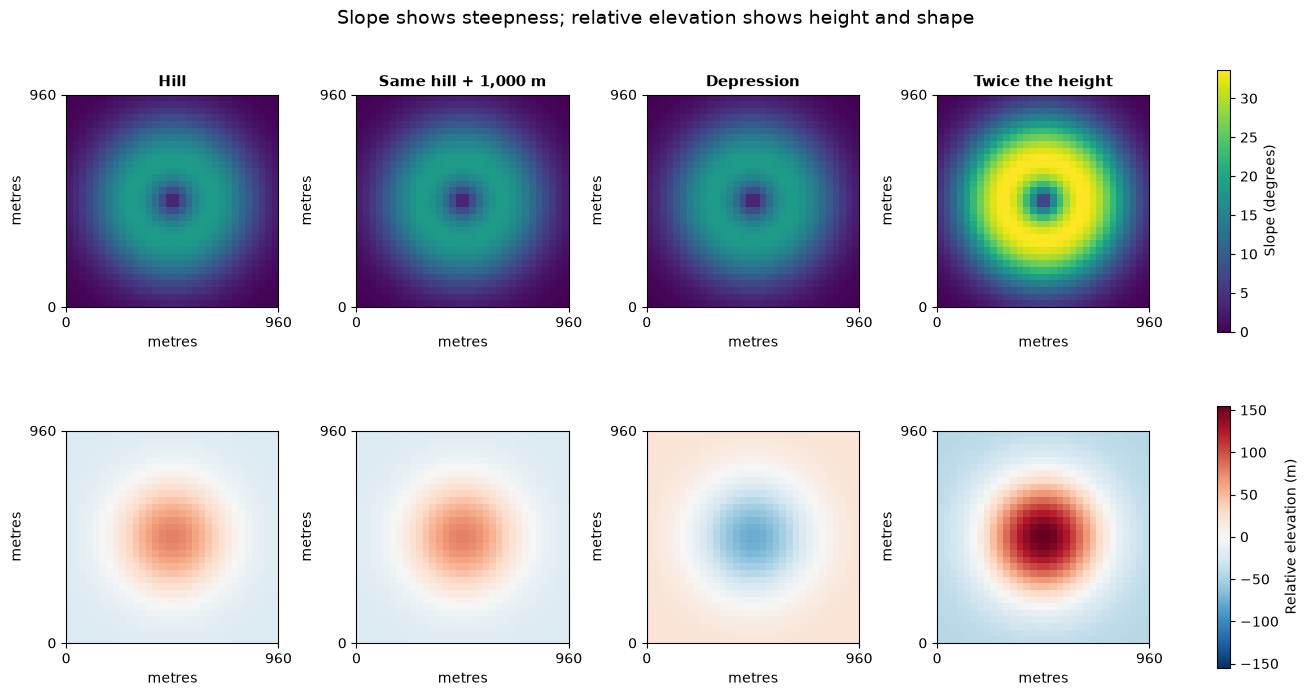

In [8]:
coordinate = (np.arange(64) - 31.5) * 30.
xx, yy = np.meshgrid(coordinate, coordinate)
hill = 100. * np.exp(-(xx**2 + yy**2) / (2. * 180.**2))
examples = [("Hill", hill), ("Same hill + 1,000 m", hill + 1000.),
            ("Depression", -hill), ("Twice the height", 2. * hill)]
toy_patches = []
for label, height in examples:
    layers = terrain(height, 30., window=11)
    crop = (slice(16, 48), slice(16, 48))
    toy_patches.append(prepare_patch(height[crop], layers["slope_deg"][crop], layers["local_elevation_std_m"][crop]))
np.testing.assert_allclose(toy_patches[0], toy_patches[1], rtol=0, atol=1e-5)
np.testing.assert_allclose(toy_patches[0][1], toy_patches[2][1], rtol=0, atol=1e-5)
np.testing.assert_allclose(toy_patches[0][0], -toy_patches[2][0], rtol=0, atol=1e-5)
np.testing.assert_allclose(toy_patches[3][0], 2. * toy_patches[0][0], rtol=0, atol=1e-5)
assert np.median(toy_patches[3][1]) > np.median(toy_patches[0][1])
fig, axes = plt.subplots(2, 4, figsize=(13, 7), constrained_layout=True)
height_limit = max(float(np.abs(p[0]).max()) for p in toy_patches)
slope_limit = max(float(p[1].max()) for p in toy_patches)
for column, ((label, _), values) in enumerate(zip(examples, toy_patches, strict=True)):
    slope_image = axes[0, column].imshow(values[1], cmap="viridis", vmin=0, vmax=slope_limit, extent=(0, 960, 0, 960))
    height_image = axes[1, column].imshow(values[0], cmap="RdBu_r", vmin=-height_limit, vmax=height_limit, extent=(0, 960, 0, 960))
    axes[0, column].set_title(label, fontsize=11, fontweight="bold")
    for ax in axes[:, column]:
        ax.set(xlabel="metres", ylabel="metres", xticks=[0, 960], yticks=[0, 960])
fig.colorbar(slope_image, ax=axes[0, :].tolist(), label="Slope (degrees)", shrink=.8)
fig.colorbar(height_image, ax=axes[1, :].tolist(), label="Relative elevation (m)", shrink=.8)
fig.suptitle("Slope shows steepness; relative elevation shows height and shape", fontsize=14)
fig.savefig(OUT / "why_slope_and_height.png", dpi=125)
plt.show()
plt.close(fig)


## Load the verified eight-orientation cache and run lunar queries

In [9]:
manifest = json.loads((DATASET / "provenance.json").read_text(encoding="utf-8"))
validate_config(manifest["config"])
assert manifest["config"]["patch_size_m"] == 960 and manifest["config"]["spacing_m"] == 30
patches = pd.read_csv(check_input(DATASET / "patches.csv", expected, evidence)).set_index("patch_id", verify_integrity=True)
roles = {(r["body"], r["region"]): r["fold"] for r in manifest["config"]["regions"]}
for r in patches[["body", "region", "role", "fold"]].drop_duplicates().to_dict("records"):
    assert r["role"] == "development" and roles.get((r["body"], r["region"])) == r["fold"]
folder = SOURCE / VIEW / SAMPLING
preprocessing = json.loads(check_input(ORIENTATION_RUN / "preprocessing.json", expected, evidence).read_text(encoding="utf-8"))
assert preprocessing["dataset_run"] == DATASET.relative_to(ROOT).as_posix()
assert preprocessing["view"] == VIEW and preprocessing["input_shape"] == [3, 32, 32]
assert preprocessing["inference_policy"] == ROTATION_REFLECTION_POLICY
assert preprocessing["source_sampling"] == SAMPLING and preprocessing["orientation_checks_passed"]
source_preprocessing = json.loads(check_input(folder / "preprocessing.json", expected, evidence).read_text(encoding="utf-8"))
scaler = preprocessing["scaler"]
assert scaler == source_preprocessing["scaler"]
assert scaler["channels"] == ["relative_elevation_m", "slope_deg", "local_elevation_std_m"]
with np.load(check_input(ORIENTATION_RUN / "embeddings.npz", expected, evidence), allow_pickle=False) as archive:
    bank_ids, bank_vectors = archive["patch_ids"].copy(), archive["cnn"].copy()
assert len(set(bank_ids)) == len(bank_ids) and bank_vectors.shape == (len(bank_ids), 64)
assert np.isfinite(bank_vectors).all()
np.testing.assert_allclose(np.linalg.norm(bank_vectors, axis=1), 1., atol=1e-5)
bank = patches.loc[bank_ids]
assert set(bank_ids) == set(patches.index[patches["view"].isin(["natural_screen", VIEW])])
lunar = bank.loc[bank["body"] == "moon"]
lunar[["region", "fold", "central_relief_m", "slope_p90_deg"]].to_csv(OUT / "lunar_queries.csv")
assert set(QUERY_IDS) <= set(lunar.index), "Choose prepared lunar IDs from the selected view's catalogue"
selected = lunar.loc[QUERY_IDS]
display(selected[["region", "fold", "central_relief_m", "slope_p90_deg"]])
pool = np.flatnonzero(bank["body"].to_numpy() == "earth")
earth = bank.iloc[pool]
assert len(earth) == 5693 and earth["region"].nunique() == 5
provenance["candidate_count"] = len(earth)
provenance["candidate_regions"] = sorted(earth["region"].unique().tolist())
cache = {}


def physical_patch(patch_id: str) -> np.ndarray:
    """Load a hash-verified prepared physical patch; never fit a new scaler."""
    item = patches.loc[patch_id]
    shard = item["shard"]
    if shard not in cache:
        with np.load(check_input(DATASET / shard, expected, evidence), allow_pickle=False) as archive:
            assert archive["valid"].all()
            cache[shard] = archive["physical"].copy()
    values = cache[shard][int(item["tensor_index"])]
    assert values.shape == (3, 32, 32) and np.isfinite(values).all()
    return values


physical = np.stack([physical_patch(p) for p in QUERY_IDS])
normalized, valid = normalize_tensors(physical, np.array(scaler["mean"]), np.array(scaler["scale"]))
assert valid.all()
checkpoint = check_input(folder / "model.pt", expected, evidence)
assert file_hash(checkpoint) == preprocessing["source_model_sha256"]
assert checkpoint.relative_to(ROOT).as_posix() == preprocessing["source_checkpoint"]
model = TerrainSimilarityCNN().to(DEVICE)
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
start = perf_counter()
query_vectors = embed(model, normalized, DEVICE, include_reflections=True)
provenance["query_inference_seconds"] = perf_counter() - start
selected_indices = bank.index.get_indexer(QUERY_IDS)
# Same inference policy for queries and candidates; allow small batch-size arithmetic differences.
np.testing.assert_allclose(query_vectors, bank_vectors[selected_indices], atol=1e-5, rtol=0)
replay_cosines = np.sum(query_vectors.astype(float) * bank_vectors[selected_indices].astype(float), axis=1) / (
    np.linalg.norm(query_vectors.astype(float), axis=1) * np.linalg.norm(bank_vectors[selected_indices].astype(float), axis=1))
assert (replay_cosines > 1. - 1e-6).all()
provenance["minimum_saved_embedding_cosine"] = float(replay_cosines.min())
provenance["max_saved_embedding_difference"] = float(np.abs(query_vectors - bank_vectors[selected_indices]).max())
print(f"Encoded {len(QUERY_IDS)} lunar queries on CPU in {provenance['query_inference_seconds']:.3f} s (excludes loading and reporting).")

,region,fold,central_relief_m,slope_p90_deg
patch_id,,,,
A3CLR22_10_Leibnitz_Beta_Plateau:full_context:144:112:960,A3CLR22_10_Leibnitz_Beta_Plateau,holdout,158.861499,14.845713
A3CLR22_2_Haworth:full_context:272:368:960,A3CLR22_2_Haworth,train,117.486652,17.540758
A3CLR22_11_Malapert_Massif:full_context:432:368:960,A3CLR22_11_Malapert_Massif,train,269.227905,18.820943


Encoded 3 lunar queries on CPU in 1.363 s (excludes loading and reporting).


## Retrieved Earth candidates

These are ranked by the trained CNN's cosine similarity alone. The physical measurements explain what the match preserves or misses; they do not alter the order. Coordinates are WGS84 patch centres, not validated access points.

**How to read each card:** the left column is the **MOON query**, repeated beside each ranked **EARTH candidate** on the right. The upper row compares **slope**; the lower row compares **relative elevation**. Both retain physical units. Warm elevation colours mean higher ground relative to the patch mean, not a stronger match.

All terrain panels retain their source raster orientation (grid-up). The inference representation averages four quarter-turns and their reflections, so a candidate may match in a rotated or mirrored orientation even when the displayed images face different directions. Relative elevation and slope use shared colour ranges within each query card. No independent height stretching makes a weak match look stronger.

**Physical measurements appear beneath every pair.** `Abs. difference` is the magnitude of the Moon–Earth difference, in that row's units. `Diff. / band` expresses it relative to a stated exploratory tolerance: **within at ≤1**, **outside at >1**. Labels and colours show the same result. The largest ratio summarizes the worst physical discrepancy; the count is a count of checks, not a similarity percentage. Neither changes the CNN ranking.

| Measurement | Meaning | Comparison band |
| --- | --- | --- |
| Median slope | Typical steepness | 1 degree |
| P90 slope | 90th percentile of steepness | 2 degrees |
| Relief | 95th minus 5th elevation percentile | Larger of 5 m or 10% of the smaller relief |
| Plane residual fraction | Departure from a fitted tilted plane, normalized by height variability | 0.1 |
| Median local elevation SD | Typical nearby height variability; not rock abundance | Larger of 1 m or 10% of the smaller local SD |

These reuse the existing physical-baseline bands, which differ from notebook 32's looser nominal coverage screen. They are not equipment limits or validated relevance thresholds. Similar measurements can still have different spatial arrangements; inspect the maps as well. Numerical labels are rounded for display; flags use the unrounded values.

The panels intentionally show their original raster orientations. Averaged embeddings do not identify a unique alignment. Do not interpret this display as registered pixel-to-pixel correspondence.


,rank,earth_region,cosine_similarity,latitude,longitude,candidate_relief_m,delta_relief_m,candidate_slope_p90_deg,delta_slope_p90_deg
0,1,atacama_san_pedro,0.7834,-23.1935,-68.4546,147.4904,-11.3711,14.9051,0.0594
1,2,atacama_san_pedro,0.7324,-23.0251,-67.8089,99.9659,-58.8956,14.5392,-0.3065
2,3,atacama_san_pedro,0.6909,-23.0252,-67.8183,113.1299,-45.7316,14.8065,-0.0392


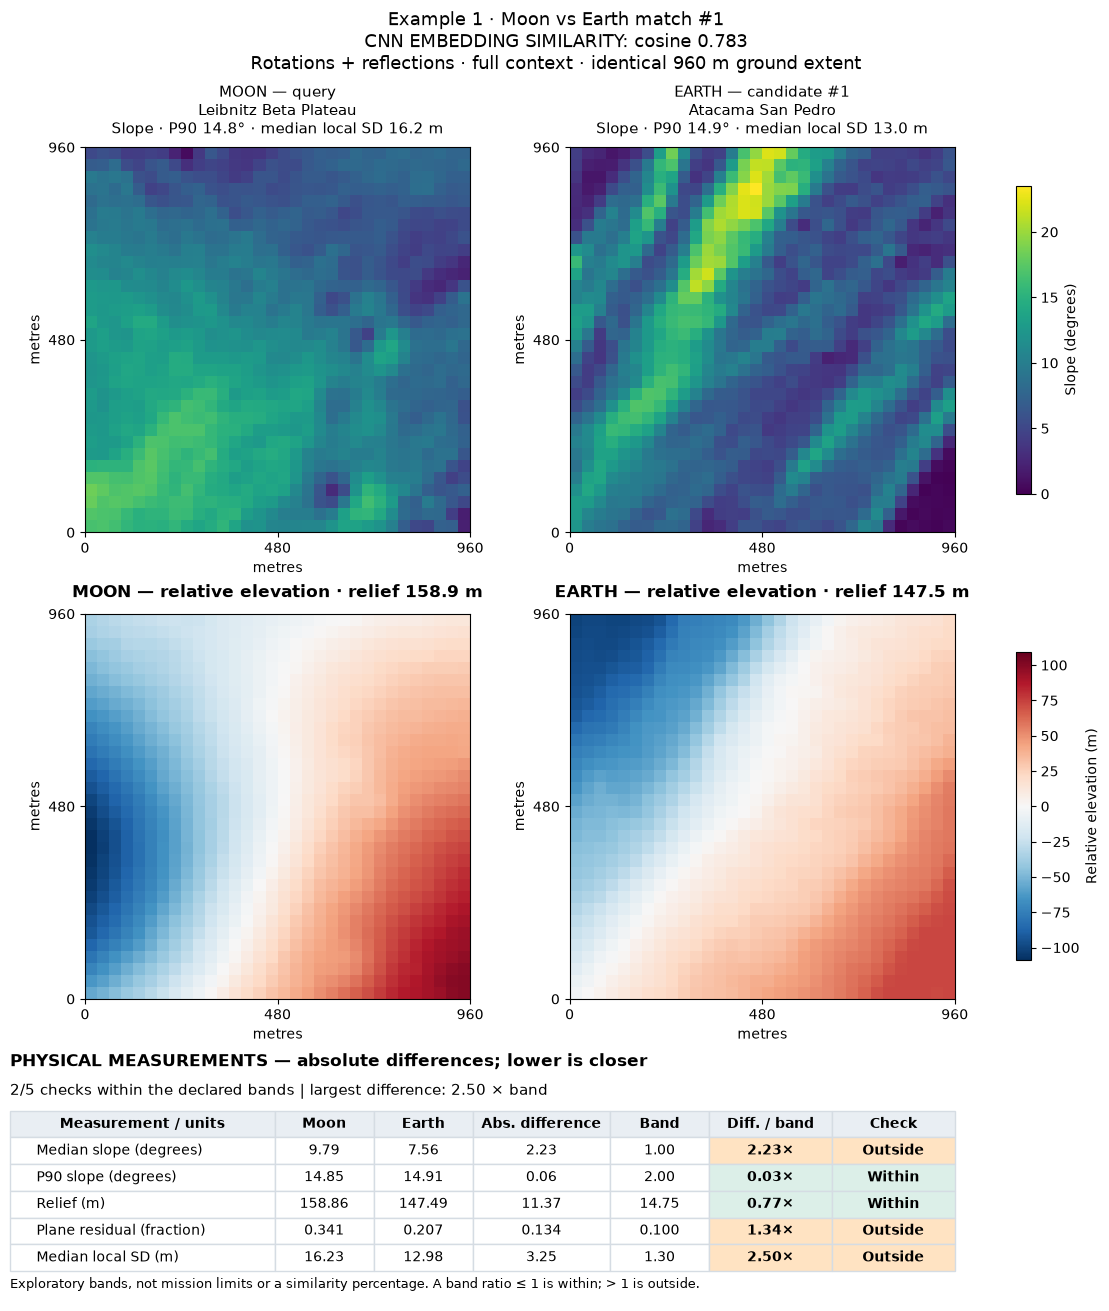

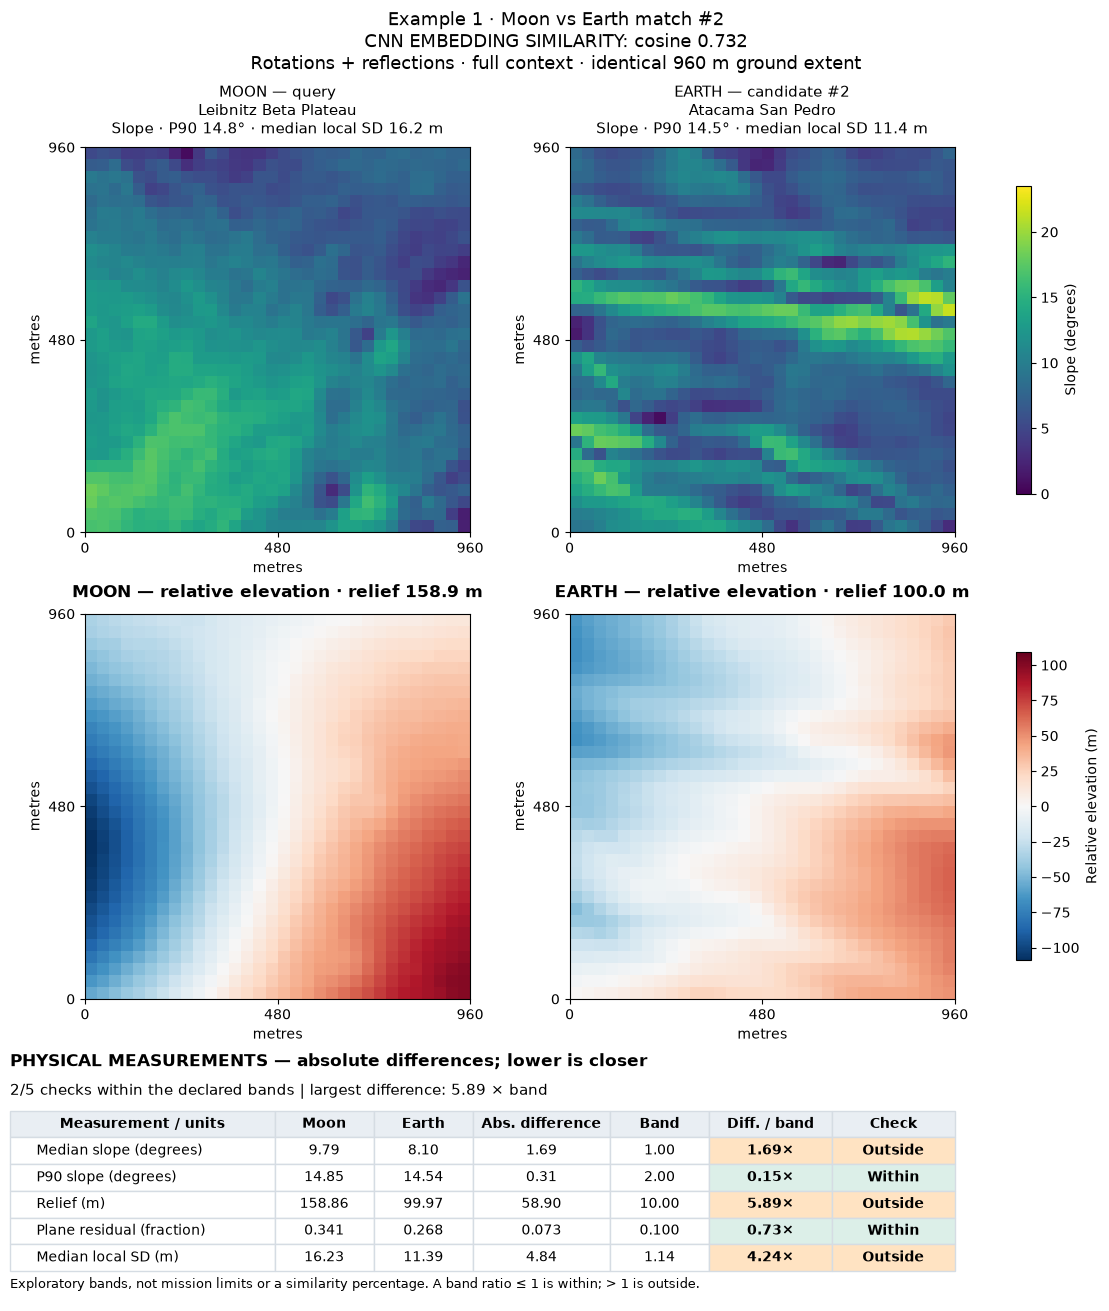

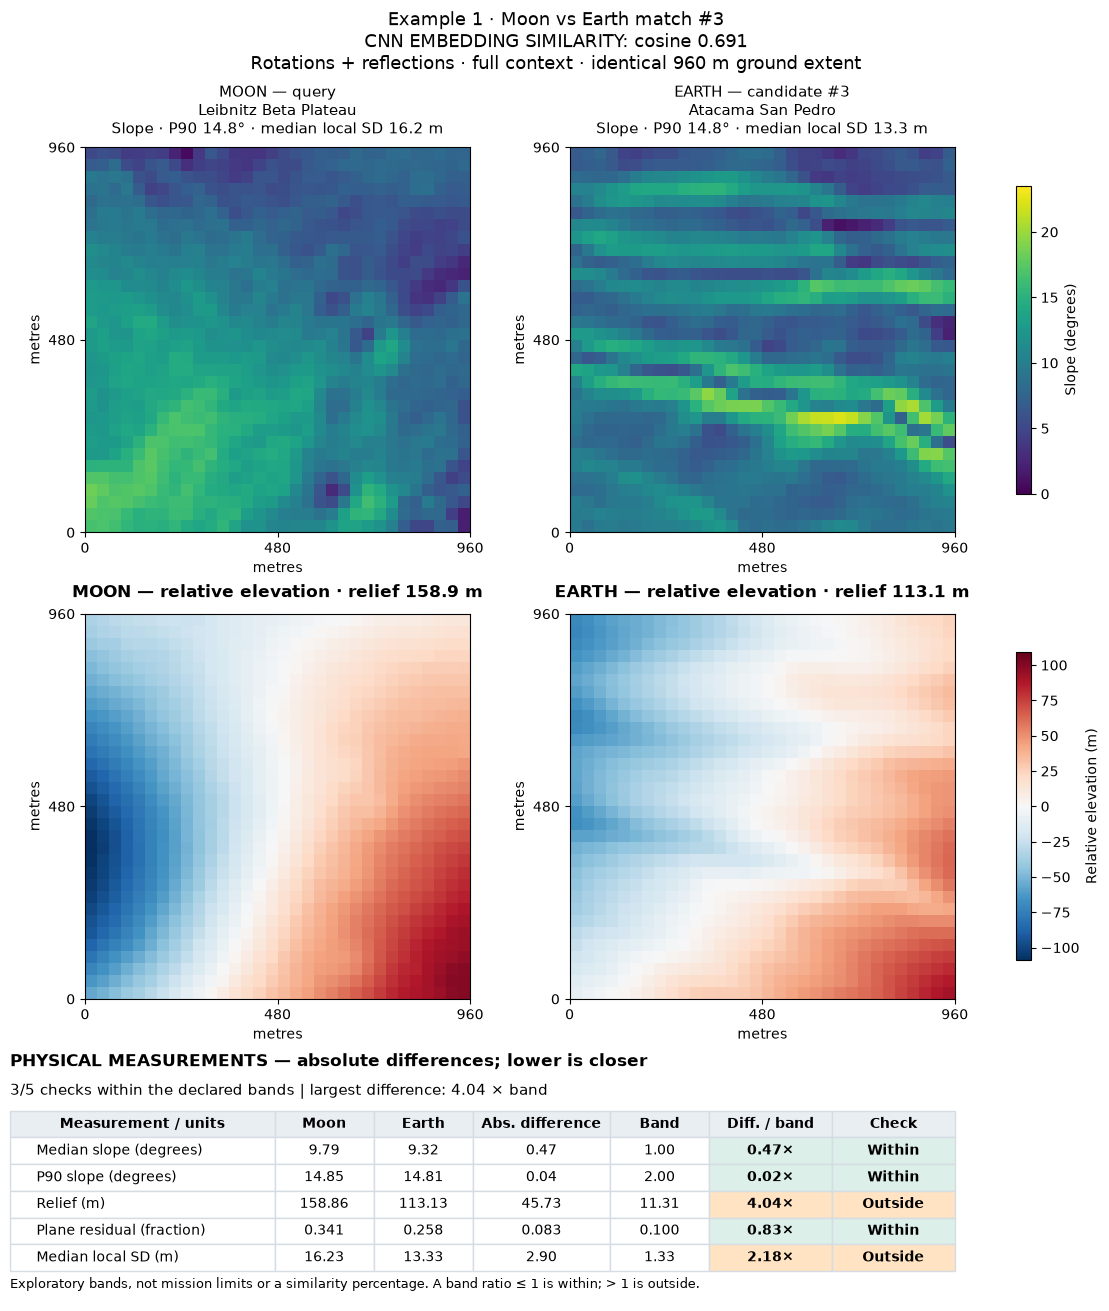

,rank,earth_region,cosine_similarity,latitude,longitude,candidate_relief_m,delta_relief_m,candidate_slope_p90_deg,delta_slope_p90_deg
0,1,wadi_rum,0.9777,29.4366,35.4146,80.0656,-37.4211,20.9132,3.3724
1,2,wadi_rum,0.9737,29.6125,35.2602,88.7576,-28.7290,20.6886,3.1479
2,3,atacama_san_pedro,0.9733,-23.1329,-68.5111,106.5016,-10.9850,19.2878,1.7470


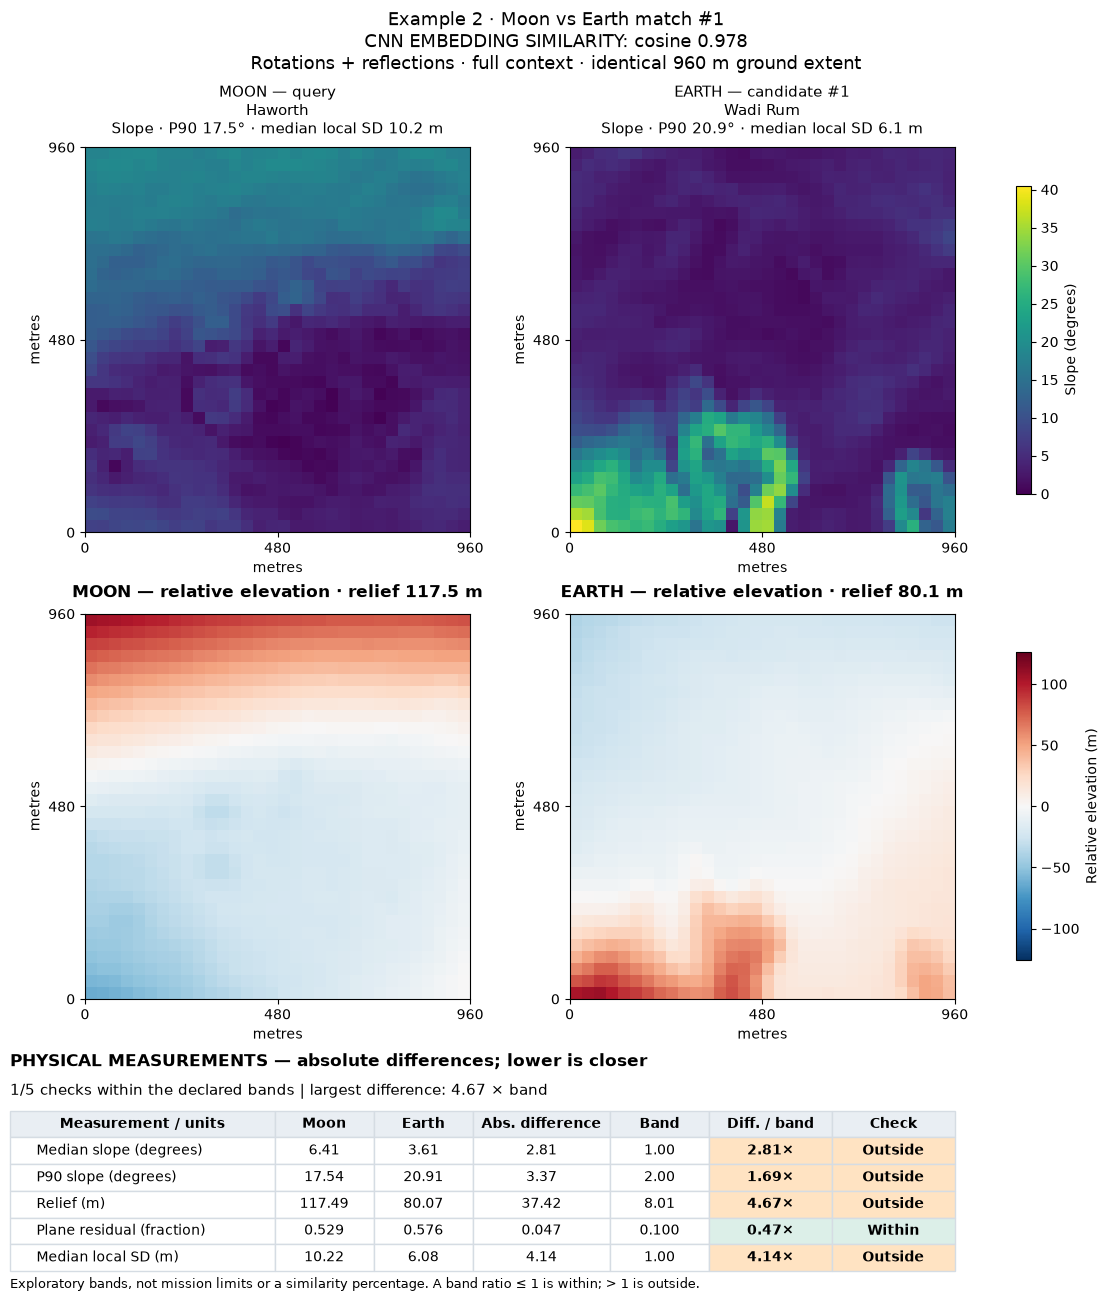

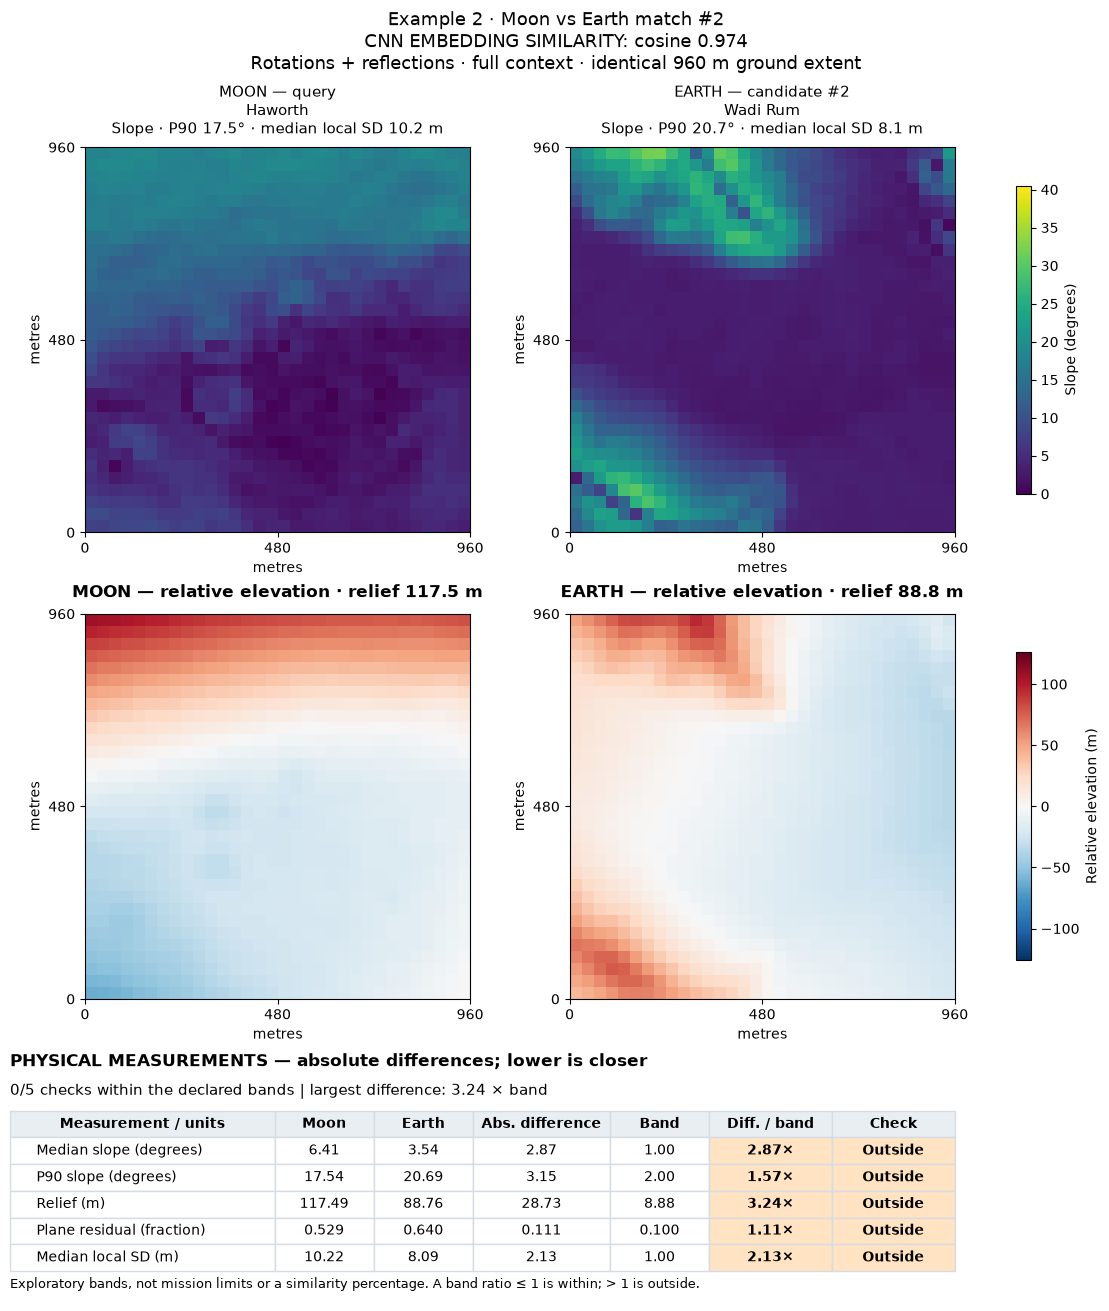

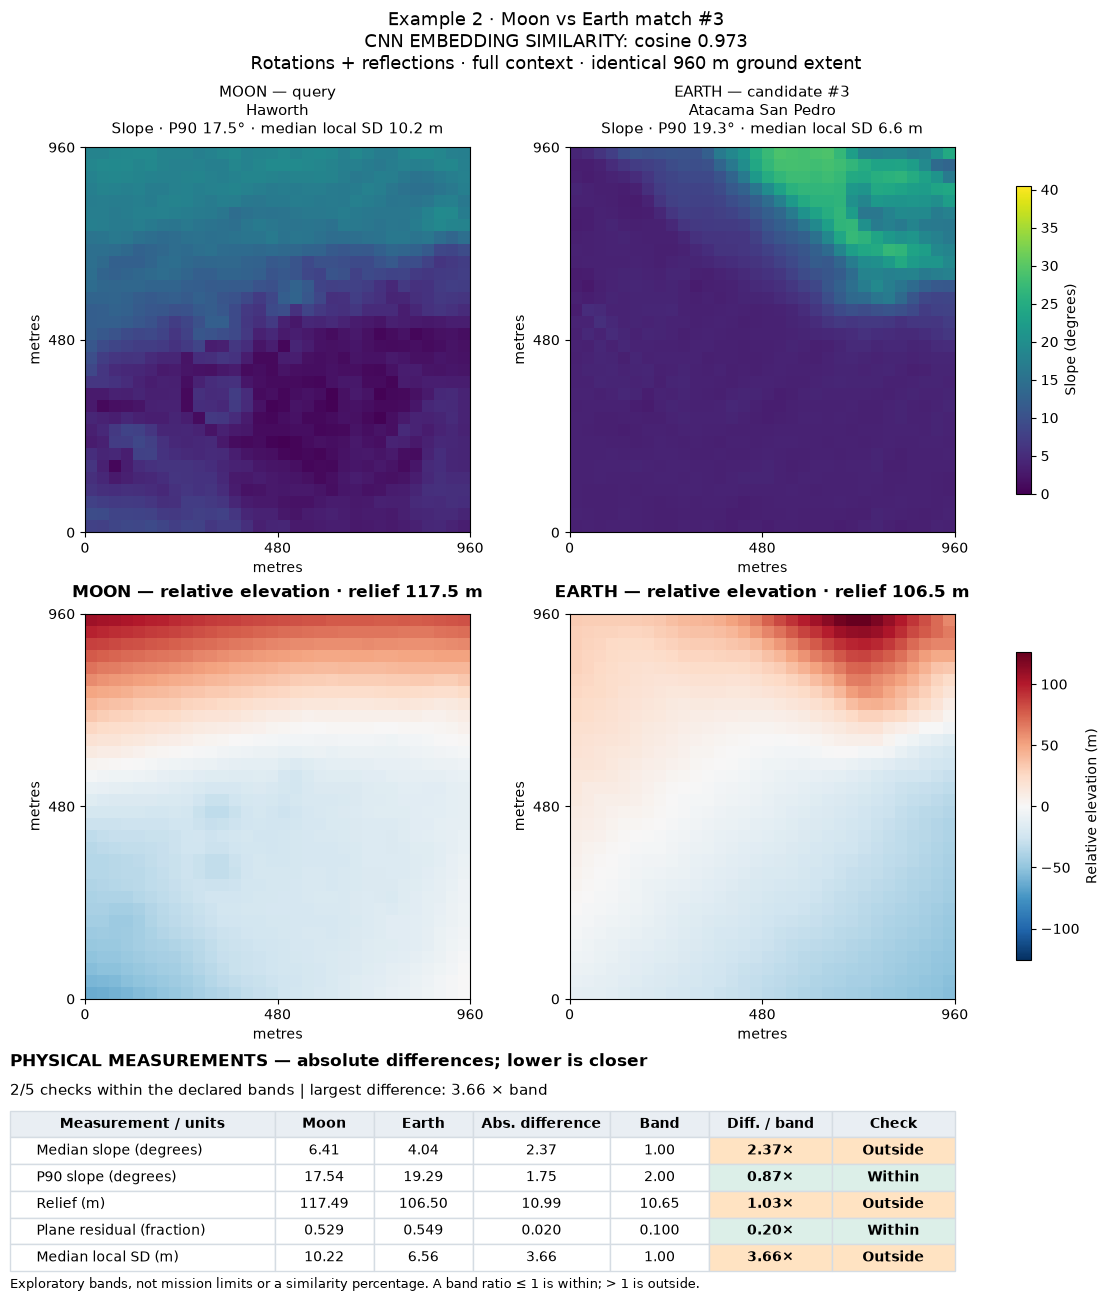

,rank,earth_region,cosine_similarity,latitude,longitude,candidate_relief_m,delta_relief_m,candidate_slope_p90_deg,delta_slope_p90_deg
0,1,atacama_san_pedro,0.5148,-22.6526,-67.8495,178.6562,-90.5717,22.1189,3.2979
1,2,atacama_san_pedro,0.5079,-22.7071,-68.2790,91.8880,-177.3399,20.2906,1.4697
2,3,atacama_san_pedro,0.4765,-22.9769,-68.5304,142.4980,-126.7299,19.8137,0.9928


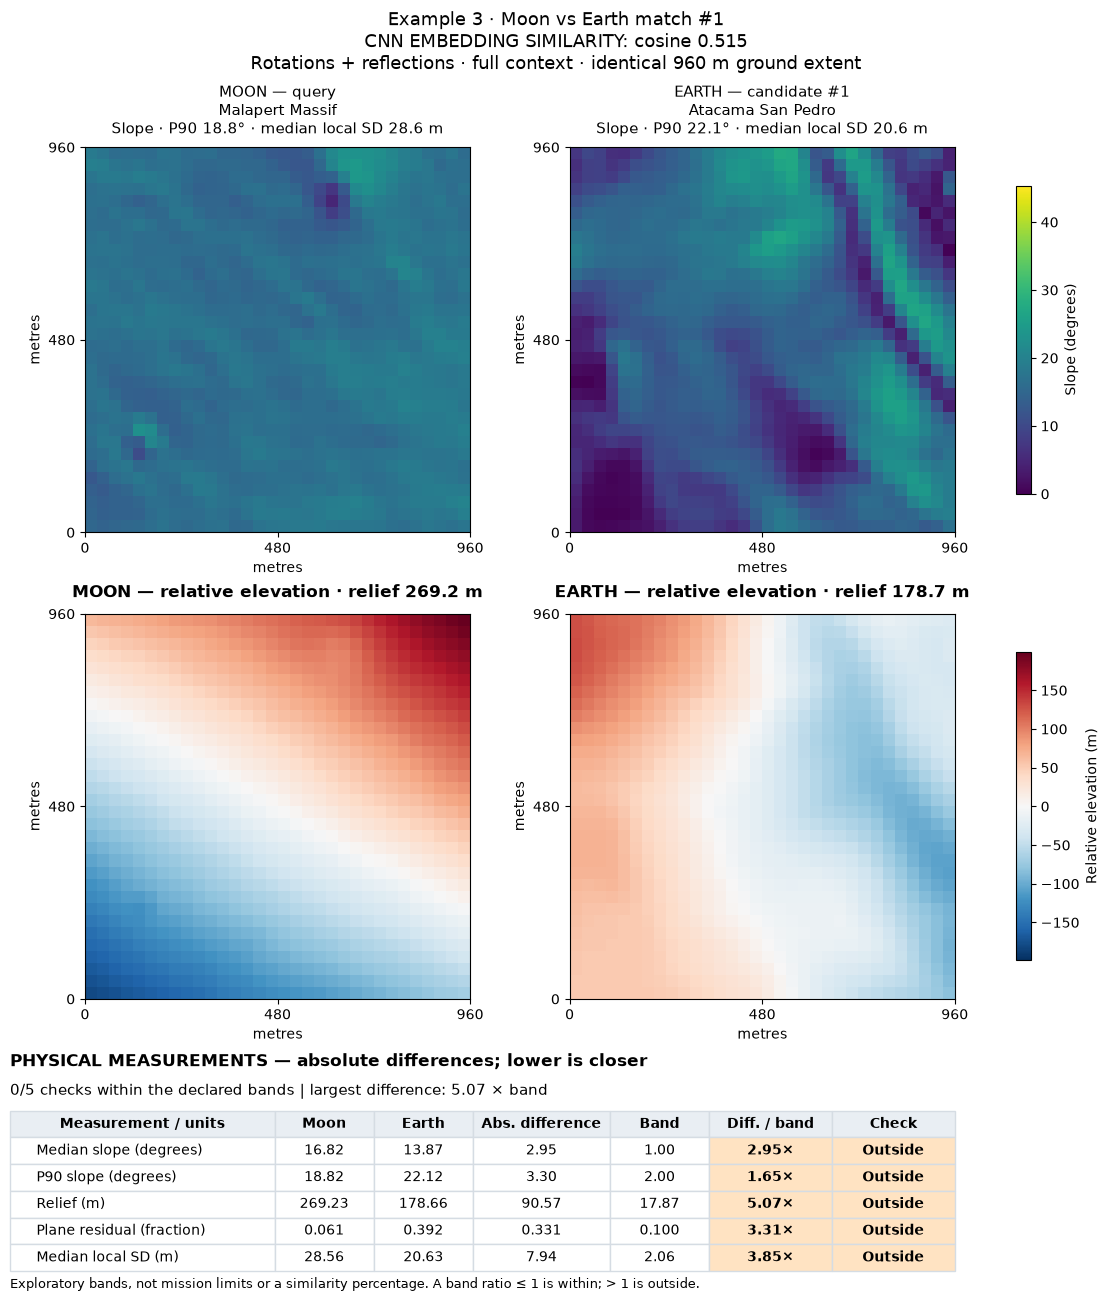

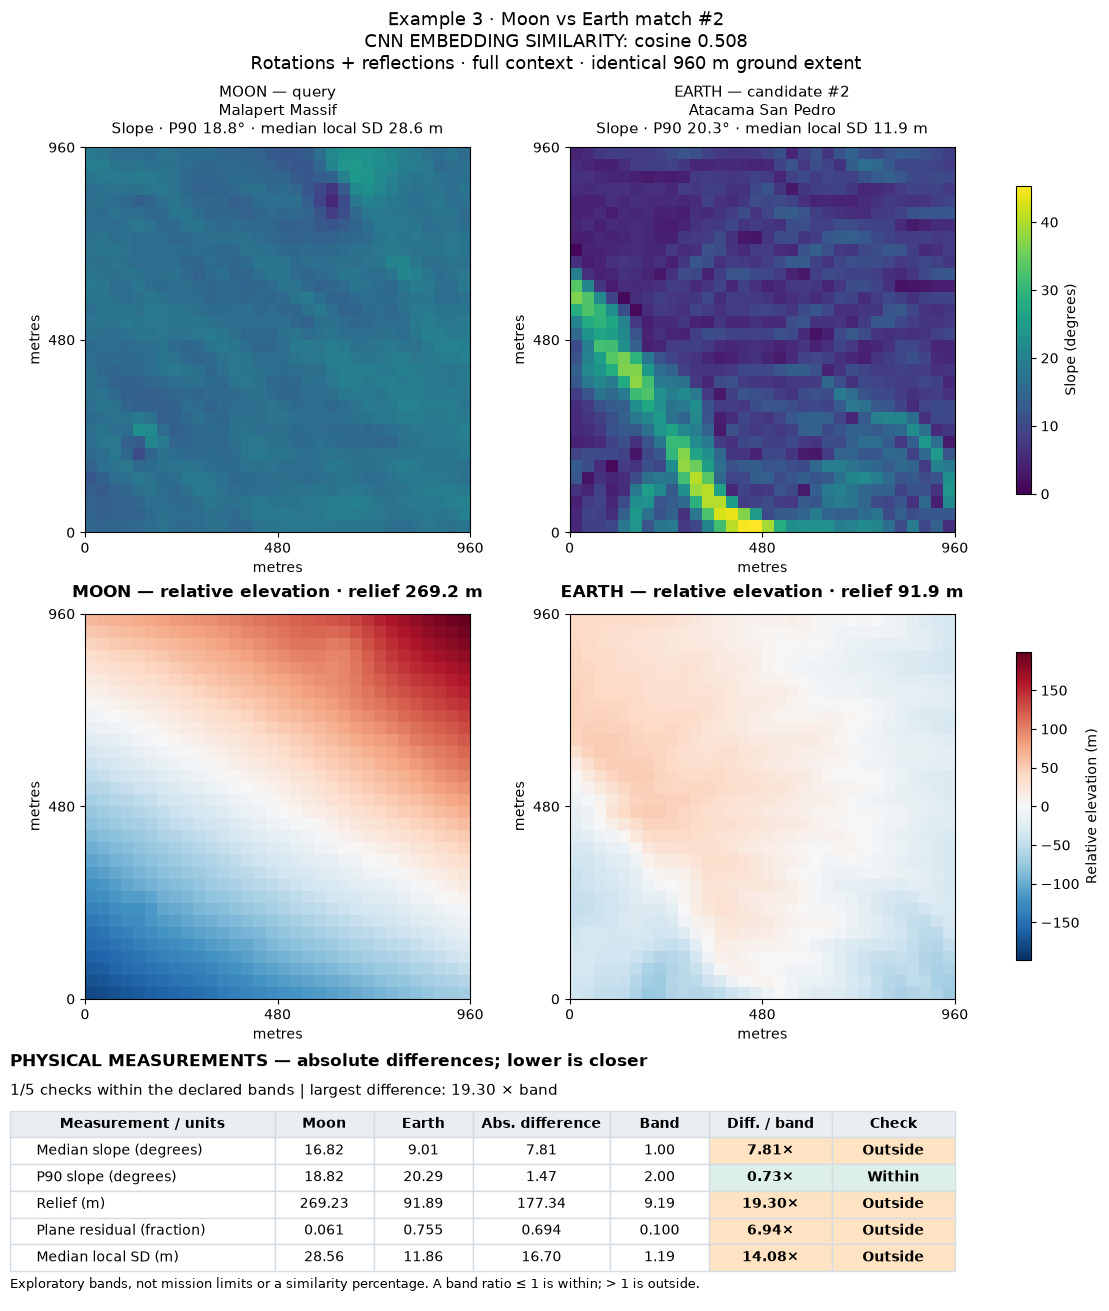

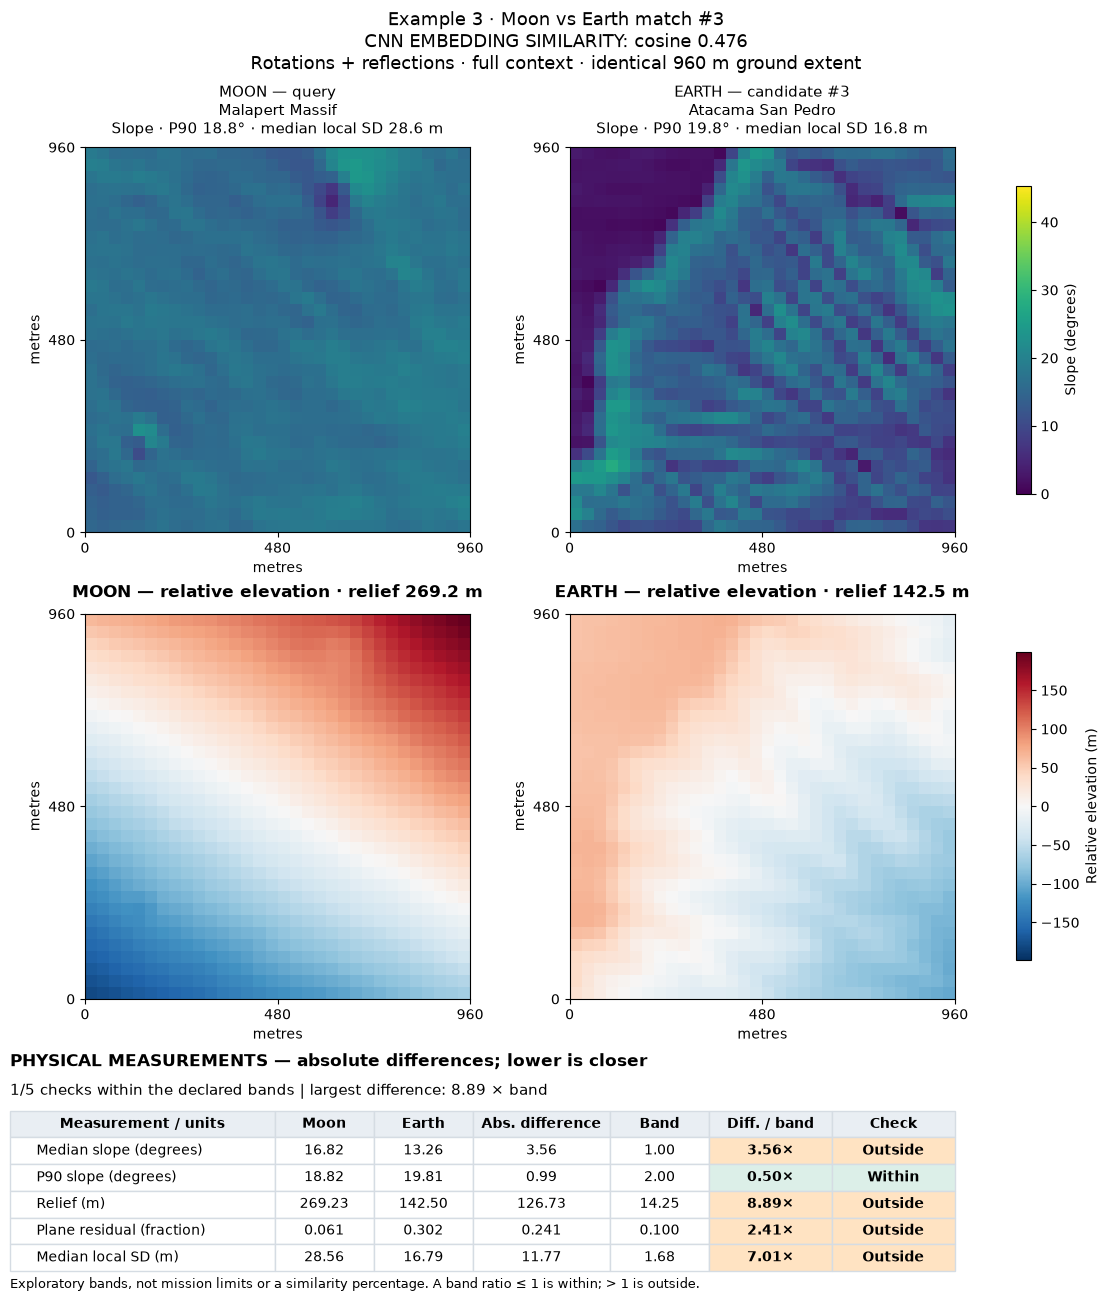

In [10]:
rows = []
comparison_rows = []
report_tables = []
METRIC_LABELS = ["Median slope (degrees)", "P90 slope (degrees)", "Relief (m)", "Plane residual (fraction)", "Median local SD (m)"]
for number, (query_id, vector) in enumerate(zip(QUERY_IDS, query_vectors, strict=True), 1):
    query = patches.loc[query_id]
    candidate_ids = earth.index.tolist()
    order, scores = cosine_top_k(vector, bank_vectors[pool], candidate_ids, TOP_K)
    saved_order, _ = cosine_top_k(bank_vectors[selected_indices[number - 1]], bank_vectors[pool], candidate_ids, TOP_K)
    assert np.array_equal(order, saved_order), "CPU replay changed top-k; inspect ties before presenting"
    # Independent brute-force cosine oracle verifies direction and candidate alignment.
    dots = [float(np.dot(vector.astype(float), v.astype(float)) / (np.linalg.norm(vector.astype(float)) * np.linalg.norm(v.astype(float))))
            for v in bank_vectors[pool]]
    oracle = sorted(range(len(dots)), key=lambda i: (-dots[i], candidate_ids[i]))[:TOP_K]
    assert order.tolist() == oracle
    chosen = earth.iloc[order]
    for rank, (candidate_id, score) in enumerate(zip(chosen.index, scores, strict=True), 1):
        candidate = patches.loc[candidate_id]
        x = float((candidate["left"] + candidate["right"]) / 2)
        y = float((candidate["bottom"] + candidate["top"]) / 2)
        lon, lat = transform(candidate["crs_wkt"], "EPSG:4326", [x], [y])
        back_x, back_y = transform("EPSG:4326", candidate["crs_wkt"], lon, lat)
        np.testing.assert_allclose([back_x[0], back_y[0]], [x, y], atol=.01, rtol=0)
        assert -180 <= lon[0] <= 180 and -90 <= lat[0] <= 90
        query_features = query[FEATURES].to_numpy(dtype=float)
        candidate_features = candidate[FEATURES].to_numpy(dtype=float)
        # Existing physical-baseline bands, not notebook 32's looser nominal screen.
        bands = np.array([1., 2., max(5., .1 * min(query_features[2], candidate_features[2])),
                          .1, max(1., .1 * min(query_features[4], candidate_features[4]))])
        differences = np.abs(candidate_features - query_features)
        discrepancies = differences / bands
        within = discrepancies <= 1.
        reference = terrain_discrepancies(query_features, candidate_features[None, :])
        physical_discrepancy = max(float(reference["with_planarity"][0]), float(reference["with_local_sd"][0]))
        np.testing.assert_allclose(discrepancies.max(), physical_discrepancy, rtol=1e-12, atol=1e-12)
        for feature, label, moon_value, earth_value, difference, band, discrepancy, included in zip(
                FEATURES, METRIC_LABELS, query_features, candidate_features, differences, bands, discrepancies, within, strict=True):
            comparison_rows.append({"example": number, "rank": rank, "query_id": query_id, "candidate_id": candidate_id,
                "feature": feature, "measurement": label, "moon": float(moon_value), "earth": float(earth_value),
                "absolute_difference": float(difference), "comparison_band": float(band),
                "difference_over_band": float(discrepancy), "within_band": bool(included)})
        rows.append({"example": number, "query_id": query_id, "query_region": query["region"], "query_fold": query["fold"],
            "rank": rank, "candidate_id": candidate_id, "earth_region": candidate["region"], "candidate_fold": candidate["fold"],
            "cosine_similarity": float(score), "latitude": lat[0], "longitude": lon[0],
            "query_relief_m": query["central_relief_m"], "candidate_relief_m": candidate["central_relief_m"],
            "delta_relief_m": candidate["central_relief_m"] - query["central_relief_m"],
            "query_slope_p90_deg": query["slope_p90_deg"], "candidate_slope_p90_deg": candidate["slope_p90_deg"],
            "delta_slope_p90_deg": candidate["slope_p90_deg"] - query["slope_p90_deg"],
            "candidate_local_sd_m": candidate["local_sd_median_m"],
            "physical_checks_within_band": int(within.sum()), "physical_discrepancy": physical_discrepancy})
    table = pd.DataFrame([r for r in rows if r["example"] == number])
    display(table[["rank", "earth_region", "cosine_similarity", "latitude", "longitude", "candidate_relief_m", "delta_relief_m", "candidate_slope_p90_deg", "delta_slope_p90_deg"]].round(4))
    ids_to_plot = [query_id, *chosen.index.tolist()]
    arrays = [physical_patch(p) for p in ids_to_plot]
    limit = max(float(np.abs(a[0]).max()) for a in arrays) or 1.
    slope_limit = max(float(a[1].max()) for a in arrays) or 1.
    pair_figures = []
    for rank, (candidate_id, score) in enumerate(zip(chosen.index, scores, strict=True), 1):
        fig = plt.figure(figsize=(11, 13), constrained_layout=True)
        grid = fig.add_gridspec(3, 2, height_ratios=[1., 1., .65])
        axes = np.array([[fig.add_subplot(grid[row, column]) for column in range(2)] for row in range(2)])
        measurement_axis = fig.add_subplot(grid[2, :])
        measurement_axis.axis("off")
        query_name = " ".join(query["region"].split("_")[2:])
        candidate = patches.loc[candidate_id]
        headings = [f"MOON — query\n{query_name}",
                    f"EARTH — candidate #{rank}\n{candidate['region'].replace('_', ' ').title()}"]
        for column, (patch_id, values, heading) in enumerate(zip(
                [query_id, candidate_id], [arrays[0], arrays[rank]], headings, strict=True)):
            item = patches.loc[patch_id]
            body = "MOON" if column == 0 else "EARTH"
            elevation_image = axes[1, column].imshow(values[0], cmap="RdBu_r", vmin=-limit, vmax=limit, extent=(0, 960, 0, 960))
            slope_image = axes[0, column].imshow(values[1], cmap="viridis", vmin=0, vmax=slope_limit, extent=(0, 960, 0, 960))
            axes[1, column].set_title(f"{body} — relative elevation · relief {item['central_relief_m']:.1f} m", fontsize=12, fontweight="bold", pad=12)
            axes[0, column].set_title(f"{heading}\nSlope · P90 {item['slope_p90_deg']:.1f}° · median local SD {item['local_sd_median_m']:.1f} m", fontsize=11, pad=10)
            for ax in axes[:, column]:
                ax.set(xticks=[0, 480, 960], yticks=[0, 480, 960], xlabel="metres", ylabel="metres")
        fig.colorbar(elevation_image, ax=axes[1, :].tolist(), label="Relative elevation (m)", shrink=.8)
        fig.colorbar(slope_image, ax=axes[0, :].tolist(), label="Slope (degrees)", shrink=.8)
        fig.suptitle(f"Example {number} · Moon vs Earth match #{rank}\nCNN EMBEDDING SIMILARITY: cosine {score:.3f}\nRotations + reflections · {VIEW.replace('_', ' ')} · identical 960 m ground extent", fontsize=13)
        comparison = [r for r in comparison_rows if r["example"] == number and r["rank"] == rank]
        checks_within = sum(r["within_band"] for r in comparison)
        worst = max(comparison, key=lambda r: r["difference_over_band"])
        measurement_axis.text(0., .99, "PHYSICAL MEASUREMENTS — absolute differences; lower is closer",
                              transform=measurement_axis.transAxes, fontsize=12, fontweight="bold", va="top")
        measurement_axis.text(0., .87, f"{checks_within}/5 checks within the declared bands | largest difference: {worst['difference_over_band']:.2f} × band",
                              transform=measurement_axis.transAxes, fontsize=11, va="top")
        table_values = []
        for r in comparison:
            decimals = 3 if r["feature"] == "plane_residual_fraction" else 2
            table_values.append([r["measurement"], f"{r['moon']:.{decimals}f}", f"{r['earth']:.{decimals}f}",
                f"{r['absolute_difference']:.{decimals}f}", f"{r['comparison_band']:.{decimals}f}",
                f"{r['difference_over_band']:.2f}×", "Within" if r["within_band"] else "Outside"])
        measure_table = measurement_axis.table(cellText=table_values,
            colLabels=["Measurement / units", "Moon", "Earth", "Abs. difference", "Band", "Diff. / band", "Check"],
            colWidths=[.28, .105, .105, .145, .105, .13, .13], cellLoc="center", bbox=[0., .12, 1., .64])
        measure_table.auto_set_font_size(False)
        measure_table.set_fontsize(10)
        for (row, column), table_cell in measure_table.get_celld().items():
            table_cell.set_edgecolor("#d5dce3")
            if row == 0:
                table_cell.set_facecolor("#e9eef3")
                table_cell.set_text_props(weight="bold")
            elif column == 0:
                table_cell.set_text_props(ha="left")
            elif column in [5, 6]:
                table_cell.set_facecolor("#dcefe8" if comparison[row - 1]["within_band"] else "#ffe3c2")
                table_cell.set_text_props(weight="bold")
        measurement_axis.text(0., .04, "Exploratory bands, not mission limits or a similarity percentage. A band ratio ≤ 1 is within; > 1 is outside.",
                              transform=measurement_axis.transAxes, fontsize=9, va="bottom")
        filename = f"example_{number}_rank_{rank}.png"
        fig.savefig(OUT / filename, dpi=125)
        pair_figures.append(f"![Moon query beside Earth candidate {rank}]({filename})")
        plt.show()
        plt.close(fig)
    lines = [f"## Example {number}: {query['region']}", f"Query: `{query_id}`", "\n\n".join(pair_figures),
             "| Rank | Earth region | Cosine | Centre latitude, longitude | Relief m (difference) | P90 slope degrees (difference) |",
             "| --- | --- | --- | --- | --- | --- |"]
    for r in table.to_dict("records"):
        lines.append(f"| {r['rank']} | {r['earth_region']} | {r['cosine_similarity']:.4f} | {r['latitude']:.5f}, {r['longitude']:.5f} | {r['candidate_relief_m']:.1f} ({r['delta_relief_m']:+.1f}) | {r['candidate_slope_p90_deg']:.1f} ({r['delta_slope_p90_deg']:+.1f}) |")
    report_tables.append("\n\n".join(lines[:3]) + "\n\n" + "\n".join(lines[3:]))
results = pd.DataFrame(rows)
assert len(results) == len(QUERY_IDS) * TOP_K
results.to_csv(OUT / "retrieval.csv", index=False)
comparisons = pd.DataFrame(comparison_rows)
assert len(comparisons) == len(results) * len(FEATURES)
comparisons.to_csv(OUT / "physical_comparison.csv", index=False)
selected[["region", "fold", "view", "left", "bottom", "right", "top", "crs_wkt"]].to_csv(OUT / "selected_queries.csv")

## Compare the spread of slopes and heights

These curves compare all cells in each patch, complementing the median, P90 and relief measurements. The vertical axis is the fraction of patch cells at or below a value. A height curve shifted horizontally means a different distribution of **relative** heights, not a different absolute altitude. Curves use the original physical units without independently stretching each patch.

Distributions do not preserve spatial arrangement: use them alongside the maps. Overlapping curves alone do not establish equivalent terrain. Rotating or mirroring a patch leaves these distributions unchanged.

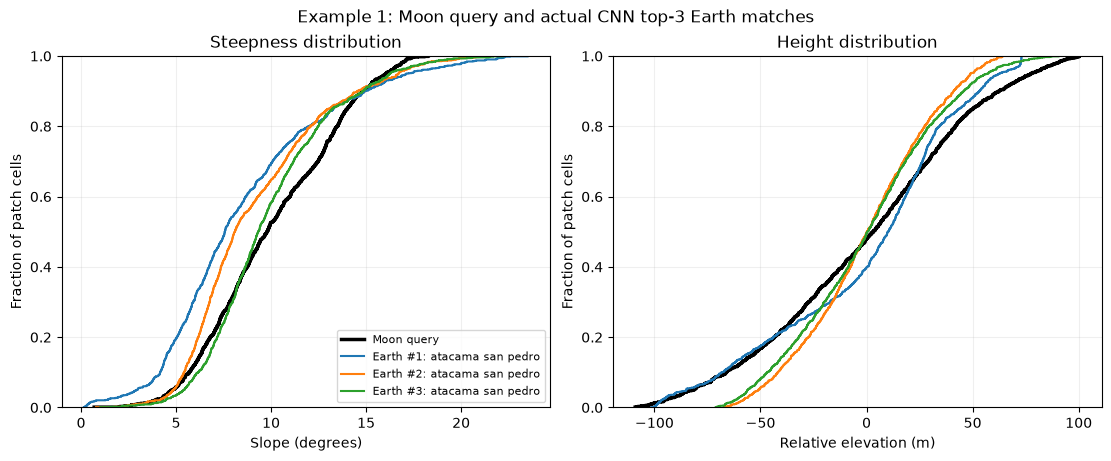

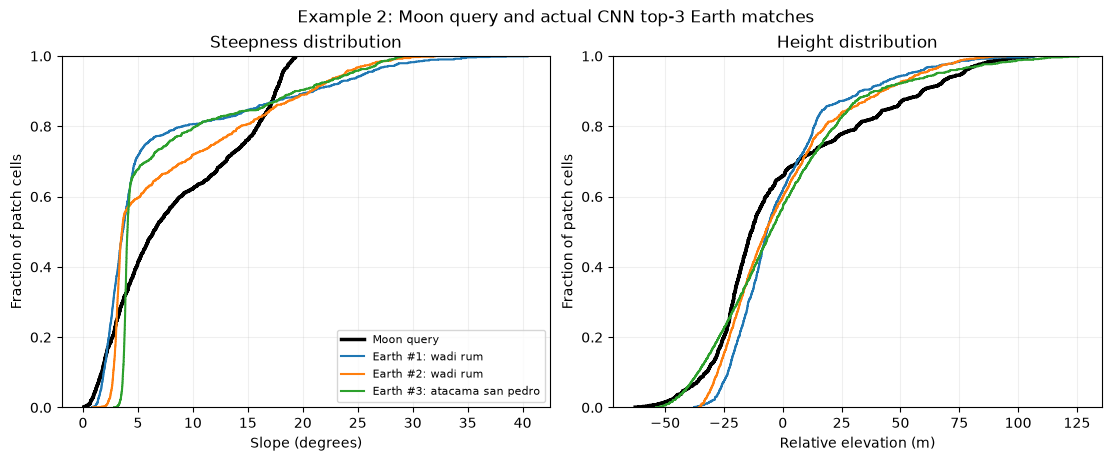

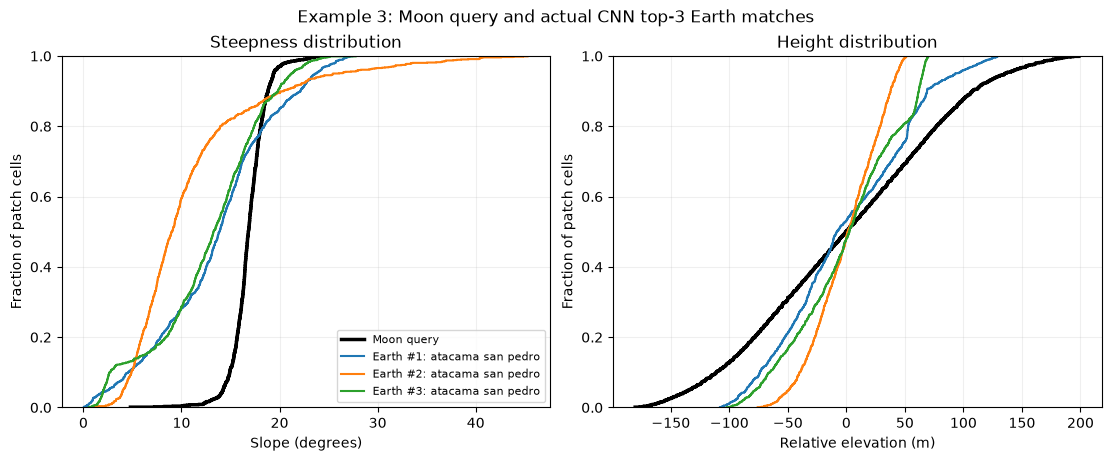

,example,rank,earth_region,cosine_similarity,physical_checks_within_band,physical_discrepancy
0,1,1,atacama_san_pedro,0.783,2,2.501
1,1,2,atacama_san_pedro,0.732,2,5.892
2,1,3,atacama_san_pedro,0.691,3,4.042
3,2,1,wadi_rum,0.978,1,4.674
4,2,2,wadi_rum,0.974,0,3.237
5,2,3,atacama_san_pedro,0.973,2,3.659
6,3,1,atacama_san_pedro,0.515,0,5.070
7,3,2,atacama_san_pedro,0.508,1,19.300
8,3,3,atacama_san_pedro,0.476,1,8.893


In [11]:
distribution_figures = []
for number, query_id in enumerate(QUERY_IDS, 1):
    chosen = results.loc[results.example == number].sort_values("rank")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
    ids = [query_id, *chosen.candidate_id.tolist()]
    labels = ["Moon query", *(f"Earth #{int(r['rank'])}: {r['earth_region'].replace('_', ' ')}" for r in chosen.to_dict("records"))]
    for position, (patch_id, label) in enumerate(zip(ids, labels, strict=True)):
        values = physical_patch(patch_id)
        for ax, channel in zip(axes, [1, 0], strict=True):
            ordered = np.sort(values[channel].ravel())
            fraction = np.arange(1, len(ordered) + 1) / len(ordered)
            ax.step(ordered, fraction, where="post", label=label,
                    linewidth=2.5 if position == 0 else 1.5, color="black" if position == 0 else None)
    axes[0].set(xlabel="Slope (degrees)", ylabel="Fraction of patch cells", title="Steepness distribution")
    axes[1].set(xlabel="Relative elevation (m)", ylabel="Fraction of patch cells", title="Height distribution")
    for ax in axes:
        ax.set_ylim(0, 1)
        ax.grid(alpha=.2)
    axes[0].legend(fontsize=8, loc="lower right")
    fig.suptitle(f"Example {number}: Moon query and actual CNN top-{TOP_K} Earth matches")
    filename = f"example_{number}_distributions.png"
    fig.savefig(OUT / filename, dpi=125)
    distribution_figures.append(f"![Example {number} slope and relative height distributions]({filename})")
    plt.show()
    plt.close(fig)
display(results[["example", "rank", "earth_region", "cosine_similarity", "physical_checks_within_band", "physical_discrepancy"]].round(3))


## What this demonstration establishes

The saved model can retrieve Earth terrain with a consistent eight-orientation representation. The maps, curves and physical table explain which steepness and height properties agree or differ. A high cosine score can coexist with large physical differences. Counts within exploratory bands are not similarity percentages or mission limits; no relevance improvement is claimed from adding reflections.

The same source patches and training normalization are retained. We remove a vertical offset, preserve height amplitude and use matching 960 m extents on a nominal 30 m grid. Equal grid spacing does not establish equal effective source resolution. Rock hazards, soil, traction, gravity, illumination, access and equipment limits remain outside this terrain-only result. The goal remains a feasibility demonstration; more training and outperforming the physical baseline are not completion requirements.

In [12]:
notebook = nbformat.read(NOTEBOOK, as_version=4)
intro = "\n\n".join(c.source for c in notebook.cells[:7] if c.cell_type == "markdown")
interpretation = notebook.cells[-2].source
sections = [intro, "![Why slope and relative elevation are both retained](why_slope_and_height.png)",
            *report_tables, notebook.cells[8].source, *distribution_figures, interpretation]
(OUT / "DEMO.md").write_text("\n\n".join(sections) + "\n", encoding="utf-8")
provenance["inputs"] = evidence
provenance["outputs"] = {p.name: file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != "provenance.json"}
provenance["status"] = "complete"
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print("Slope and relative elevation demonstration:", OUT / "DEMO.md")
print("Saved weights; eight-orientation inference; physical measurements explain, but do not rerank, the matches.")

Slope and relative elevation demonstration: .\reports\terrain-similarity-oriented-demo\20261102T143701244138Z\DEMO.md
Saved weights; eight-orientation inference; physical measurements explain, but do not rerank, the matches.
